# Analyse de données et apprentissage automatique
## Projet : analyse et prédiction des prix d’ordinateurs

Nous allons prédire le prix d’un ordinateur à partir de ses caractéristiques.

**Objectif :** préparer les données, entraîner des modèles et comparer leurs erreurs.

**Données et source.** Chaque ligne décrit un ordinateur. `price` est le prix à prédire. Le jeu utilisé est disponible dans le [dépôt GitHub du projet](https://github.com/ImagineYoureAFrog/Laptop-Price/tree/main/computer-prices-2025) ([fichier CSV](https://github.com/ImagineYoureAFrog/Laptop-Price/blob/main/computer-prices-2025/computer_prices_all.csv)). Le jeu d’origine est présenté sur la [page Computer Prices 2025](https://www.kaggle.com/competitions/computer-prices-2025/data).

Nous vérifions les données avant de construire les modèles.

## 1. Analyse exploratoire des données

Ces vérifications servent à choisir les variables et à préparer les données.

### Chargement des données

On charge le fichier d’entraînement, qui contient les prix connus.

In [8]:
# Dépendances : pandas, IPython, matplotlib et scikit-learn. Si besoin, exécuter : %pip install pandas matplotlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_URL = "https://raw.githubusercontent.com/ImagineYoureAFrog/Laptop-Price/main/computer-prices-2025"
train_url = f"{DATA_URL}/computer_prices_all.csv"
train = pd.read_csv(train_url)

print(f"Données chargées depuis : {train_url}")

Données chargées depuis : https://raw.githubusercontent.com/ImagineYoureAFrog/Laptop-Price/main/computer-prices-2025/computer_prices_all.csv


**Résultat :** le notebook charge le CSV du projet avec les prix connus.

### Dimensions et aperçu des données

L’aperçu montre les colonnes et quelques exemples.

In [9]:
print(f"Jeu de données : {train.shape[0]:,} lignes × {train.shape[1]} colonnes")

display(train.head())

Jeu de données : 100,000 lignes × 34 colonnes


,ID,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,cpu_cores,cpu_threads,cpu_base_ghz,cpu_boost_ghz,gpu_brand,gpu_model,gpu_tier,vram_gb,ram_gb,storage_type,storage_gb,storage_drive_count,display_type,display_size_in,resolution,refresh_hz,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price
0,0,Desktop,Samsung,Samsung Forge XDI,2022,Windows,ATX,Intel,Intel i5-11129,3,12,24,2.8,3.8,NVIDIA,RTX 40 60,2,6,16,NVMe,1024,1,LED,27.0,2560x1440,90,0,0,750,Wi-Fi 6,5.1,11.00,36,1383.99
1,1,Laptop,Samsung,Samsung Pro KM8,2022,Windows,Mainstream,Intel,Intel i7-11114,4,12,24,2.6,3.6,NVIDIA,RTX 40 80,4,10,64,NVMe,512,1,OLED,16.0,1920x1080,90,56,120,0,Wi-Fi 6,5.3,2.03,12,2274.99
2,2,Desktop,Lenovo,Lenovo Strix BIE,2024,macOS,SFF,AMD,AMD Ryzen 5 5168,2,8,16,2.6,3.6,NVIDIA,RTX 40 50,1,4,8,NVMe,512,2,LED,32.0,3440x1440,120,0,0,850,Wi-Fi 6,5.0,7.00,24,1879.99
3,3,Desktop,Dell,Dell Cube AXR,2024,Windows,ATX,AMD,AMD Ryzen 5 7550,2,6,12,2.6,3.6,AMD,RX 7000 60,2,6,16,HDD,512,2,IPS,27.0,3440x1440,120,0,0,650,Wi-Fi 6,5.2,6.00,36,1331.99
4,4,Laptop,Gigabyte,Gigabyte Pro IX1,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,16,32,2.8,3.9,NVIDIA,RTX 30 80 Ti,5,12,96,NVMe,256,1,Mini-LED,15.6,2560x1600,90,80,90,0,Wi-Fi 6,5.2,1.50,12,2681.99


**Résultat :** les 100 000 ordinateurs sont décrits par 34 colonnes, dont `price`, la valeur à prédire. Il reste donc 33 variables candidates avant le tri.

### Variables et types

On distingue les nombres des catégories pour savoir comment les préparer.

In [ ]:
feature_overview = pd.DataFrame({
    "feature": train.columns,
    "dtype": train.dtypes.astype(str).values,
})
display(feature_overview)

,feature,dtype
0,ID,int64
1,device_type,str
2,brand,str
3,model,str
4,release_year,int64
5,os,str
6,form_factor,str
7,cpu_brand,str
8,cpu_model,str
9,cpu_tier,int64


**Résultat :** le tableau distingue 21 colonnes numériques et 13 colonnes catégorielles, en comptant le prix.

### Statistiques descriptives

Ces résumés donnent l’échelle et les valeurs fréquentes de chaque variable.

In [ ]:
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,100000.0,NaN,NaN,NaN,49999.5,28867.657797,0.0,24999.75,49999.5,74999.25,99999.0
device_type,100000,2,Laptop,59844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,100000,10,Lenovo,15992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,100000,99036,ASUS Slim R6S,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,100000.0,NaN,NaN,NaN,2022.32085,2.025761,2018.0,2021.0,2023.0,2024.0,2025.0
os,100000,4,Windows,71817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
form_factor,100000,10,Mainstream,17819,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cpu_brand,100000,3,Intel,52774,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cpu_model,100000,26971,Apple M2 Pro,1389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cpu_tier,100000.0,NaN,NaN,NaN,3.15349,1.373175,1.0,2.0,3.0,4.0,6.0


**Résultat :** le prix moyen est de 1 928,76 et le prix médian de 1 863,99. La moyenne est tirée vers le haut par les ordinateurs les plus chers. Le prix maximum atteint 10 984,99, près de six fois la médiane. Ces valeurs élevées peuvent peser davantage dans la RMSE, qui pénalise fortement les grandes erreurs.

### Valeurs manquantes, doublons et cardinalité

On cherche les données manquantes, les doublons et les colonnes avec trop de valeurs différentes.

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean().mul(100).round(2),
    "distinct_values": train.nunique(dropna=True),
}).sort_values(["missing_count", "distinct_values"], ascending=[False, True])

display(missing_summary)
print(f"Lignes dupliquées : {train.duplicated().sum():,}")

,missing_count,missing_percent,distinct_values
device_type,0,0.0,2
cpu_brand,0,0.0,3
os,0,0.0,4
gpu_brand,0,0.0,4
storage_type,0,0.0,4
storage_drive_count,0,0.0,4
wifi,0,0.0,4
warranty_months,0,0.0,4
storage_gb,0,0.0,5
bluetooth,0,0.0,5


Lignes dupliquées : 0


**Résultat :** aucune cellule n’est manquante et aucune ligne n’est répétée. En revanche, `model` a 99 036 valeurs différentes pour 100 000 ordinateurs. Un modèle pourrait mémoriser ces noms au lieu d’apprendre le lien entre les caractéristiques et le prix. Cette colonne est donc écartée. La diversité des noms de `cpu_model` pose aussi un problème, que l’on vérifie plus loin.

### Résumés par type de variable

On regarde séparément les nombres et les catégories pour mieux comprendre leur contenu.

In [ ]:
numeric_columns = train.select_dtypes(include="number").columns.tolist()
categorical_columns = train.select_dtypes(exclude="number").columns.tolist()

print(f"Variables numériques ({len(numeric_columns)}) : {numeric_columns}")
print(f"Variables non numériques ({len(categorical_columns)}) : {categorical_columns}")

if numeric_columns:
    display(train[numeric_columns].describe().T)
if categorical_columns:
    display(train[categorical_columns].describe().T)

Variables numériques (21) : ['ID', 'release_year', 'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_gb', 'storage_drive_count', 'display_size_in', 'refresh_hz', 'battery_wh', 'charger_watts', 'psu_watts', 'bluetooth', 'weight_kg', 'warranty_months', 'price']
Variables non numériques (13) : ['device_type', 'brand', 'model', 'os', 'form_factor', 'cpu_brand', 'cpu_model', 'gpu_brand', 'gpu_model', 'storage_type', 'display_type', 'resolution', 'wifi']


,count,mean,std,min,25%,50%,75%,max
ID,100000.0,49999.500000,28867.657797,0.00,24999.75,49999.50,74999.25,99999.00
release_year,100000.0,2022.320850,2.025761,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.153490,1.373175,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.515740,5.044092,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.372700,9.718426,4.00,12.00,16.00,24.00,56.00
cpu_base_ghz,100000.0,2.591322,0.336435,2.00,2.40,2.60,2.80,3.40
cpu_boost_ghz,100000.0,3.531310,0.350024,2.80,3.30,3.50,3.80,4.50
gpu_tier,100000.0,2.991350,1.459643,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.152180,3.964926,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.706400,31.902684,8.00,16.00,32.00,64.00,144.00


,count,unique,top,freq
device_type,100000,2,Laptop,59844
brand,100000,10,Lenovo,15992
model,100000,99036,ASUS Slim R6S,3
os,100000,4,Windows,71817
form_factor,100000,10,Mainstream,17819
cpu_brand,100000,3,Intel,52774
cpu_model,100000,26971,Apple M2 Pro,1389
gpu_brand,100000,4,NVIDIA,54712
gpu_model,100000,49,Apple Integrated,18922
storage_type,100000,4,NVMe,45059


**Résultat :** il y a 21 colonnes numériques et 13 catégorielles, prix compris. `cpu_model` compte 26 971 noms, alors que `gpu_model` n’en compte que 49. Ce nombre réduit pourrait sembler pratique, mais il ne garantit pas que les noms décrivent correctement le matériel. La vérification suivante montre des contradictions pour les deux colonnes. `model` est presque unique pour chaque ligne, ce qui confirme qu’il ne faut pas l’utiliser comme caractéristique.

### Corrélations et variables redondantes

La corrélation de Spearman compare le classement des valeurs plutôt que leurs unités. Elle va de −1 à +1. Une valeur proche de +1 signifie que les deux variables ont tendance à augmenter ensemble. Une valeur proche de −1 signifie que l’une augmente quand l’autre baisse. Près de 0, leur lien est faible. Cela permet de comparer des variables comme la RAM et le prix, même si elles ne sont pas mesurées dans la même unité. Cette mesure repère des liens, mais ne prouve ni une cause ni la qualité d’un modèle.

On vérifie aussi si des combinaisons résument mieux plusieurs caractéristiques : le nombre de cœurs avec la fréquence du processeur, le niveau du GPU avec sa mémoire vidéo, et la RAM avec le stockage. Pour l’écran, on convertit la résolution en nombre total de pixels, puis on calcule aussi la densité de pixels en tenant compte de la taille de l’écran. On compare les deux au prix pour choisir une seule mesure numérique. Ces corrélations montrent des liens dans les données, mais ne remplacent pas l’évaluation des modèles.

,corr_spearman_price
ram_gb,0.795
gpu_tier,0.786
cpu_tier,0.782
cpu_cores,0.743
cpu_threads,0.604
cpu_base_ghz,0.545
cpu_boost_ghz,0.523
vram_gb,0.330
psu_watts,-0.137
charger_watts,0.131


,feature_1,feature_2,corr_spearman_abs
0,cpu_base_ghz,cpu_boost_ghz,0.960
1,cpu_tier,cpu_cores,0.957
2,gpu_tier,ram_gb,0.941
3,cpu_tier,ram_gb,0.931
4,cpu_cores,cpu_threads,0.899
5,cpu_cores,ram_gb,0.895
6,cpu_tier,gpu_tier,0.856
7,cpu_tier,cpu_threads,0.856
8,charger_watts,psu_watts,0.847
9,battery_wh,psu_watts,0.845


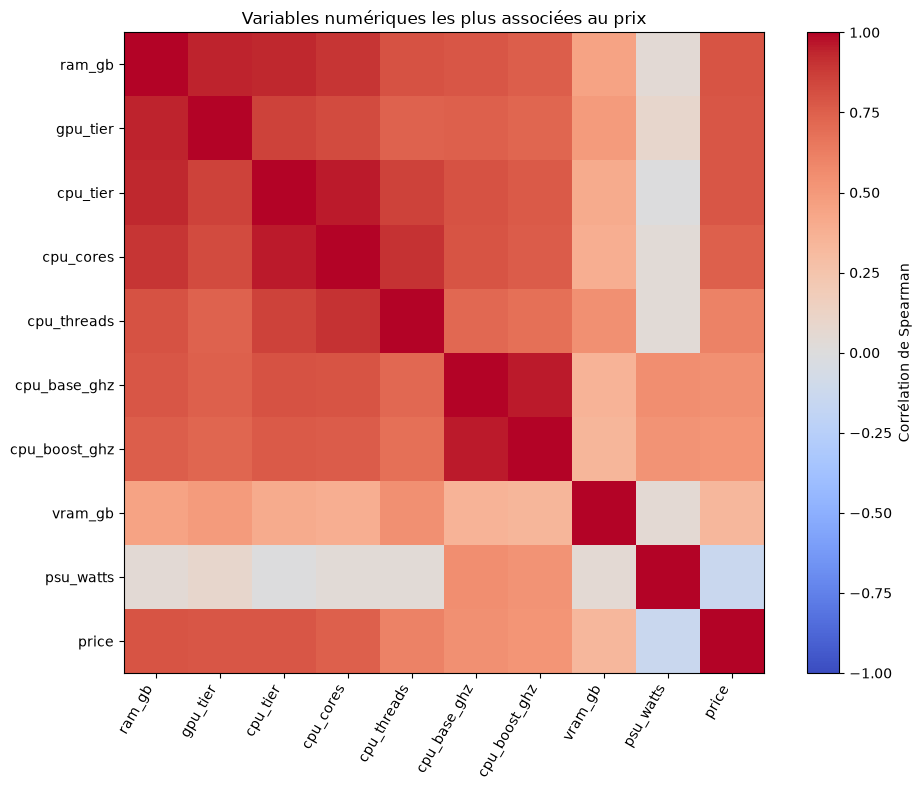

ModuleNotFoundError: No module named 'scipy'

In [10]:
numeric_features = train.select_dtypes(include="number").columns.drop(["ID", "price"])
corr_data = train[numeric_features.tolist() + ["price"]]
spearman_corr = corr_data.corr(method="spearman")

price_corr = pd.DataFrame({
    "corr_spearman_price": spearman_corr["price"].drop("price")
}).sort_values("corr_spearman_price", key=lambda values: values.abs(), ascending=False)
display(price_corr.head(12).round(3))

abs_corr = spearman_corr.drop(index="price", columns="price").abs()
upper_corr = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
correlated_pairs = (
    upper_corr.stack().rename("corr_spearman_abs").sort_values(ascending=False)
    .rename_axis(["feature_1", "feature_2"]).reset_index()
)
display(correlated_pairs.head(12).round(3))

plot_features = price_corr.head(9).index.tolist() + ["price"]
plot_corr = spearman_corr.loc[plot_features, plot_features]
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(plot_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(plot_features)), plot_features, rotation=60, ha="right")
ax.set_yticks(range(len(plot_features)), plot_features)
fig.colorbar(image, ax=ax, label="Corrélation de Spearman")
ax.set_title("Variables numériques les plus associées au prix")
fig.tight_layout()
plt.show()

feature_combinations = pd.DataFrame({
    "cpu_cores_x_boost": train["cpu_cores"] * train["cpu_boost_ghz"],
    "cpu_tier_x_cores_x_boost": train["cpu_tier"] * train["cpu_cores"] * train["cpu_boost_ghz"],
    "gpu_tier_x_vram": train["gpu_tier"] * train["vram_gb"],
    "ram_plus_log_storage": train["ram_gb"] + np.log1p(train["storage_gb"]),
})
composite_corr = pd.DataFrame({
    "corr_spearman_price": feature_combinations.corrwith(train["price"], method="spearman"),
}).sort_values("corr_spearman_price", key=lambda values: values.abs(), ascending=False)
display(composite_corr.round(3))

resolution_parts = train["resolution"].str.extract(r"^(\d+)\s*[xX×]\s*(\d+)$")
if resolution_parts.isna().any().any():
    raise ValueError("Certaines résolutions ne sont pas au format largeur x hauteur.")
resolution_width = resolution_parts[0].astype(int)
resolution_height = resolution_parts[1].astype(int)
resolution_pixels = resolution_width * resolution_height
pixel_density = np.sqrt(resolution_width**2 + resolution_height**2) / train["display_size_in"]
resolution_comparison = pd.DataFrame({
    "corr_spearman_price": {
        "resolution_pixels": resolution_pixels.corr(train["price"], method="spearman"),
        "pixel_density": pixel_density.corr(train["price"], method="spearman"),
    }
})
display(resolution_comparison.round(3))

**Résultat :** les liens individuels les plus forts avec le prix sont `ram_gb` (0,795), `gpu_tier` (0,786) et `cpu_tier` (0,782). `cpu_cores` est aussi lié au prix (0,743), mais il donne presque la même information que `cpu_tier` : leur corrélation entre eux est de 0,957. Les fréquences de base et maximale sont encore plus proches (0,960). Leurs liens avec le prix sont voisins : 0,545 pour `cpu_base_ghz` et 0,523 pour `cpu_boost_ghz`. On pourra tester un modèle qui ne garde qu'une seule des deux fréquences pour comparer avec ceux gardant les deux. Il en va de même pour `cpu_tier` et `cpu_cores`, qui semblent redondants.

Quatre combinaisons ont été calculées. `cpu_cores × cpu_boost_ghz` atteint 0,724 avec le prix. C’est moins que `cpu_cores` seul (0,743) et que `cpu_tier` (0,782). Le produit se semble donc pas améliorer la description de l'ordinateur. La combinaison `cpu_tier × cpu_cores × cpu_boost_ghz` atteint 0,749, elle aussi sous `cpu_tier` seul. On pourra tester des modèles avec ces combinaisons, mais elles ne semblent pas plus utiles que les variables originales a première vue.

`gpu_tier × vram_gb` atteint 0,450, bien en dessous de `gpu_tier` seul (0,786). Le niveau du GPU est déjà fortement lié au prix, mais le multiplier par la mémoire vidéo semble pas renforcer ce lien. Enfin, `ram_gb + log1p(storage_gb)` atteint 0,799 contre 0,795 pour la RAM seule. `log1p` réduit l’écart entre les petites et grandes capacités de stockage avant de les additionner à la RAM. C’est le meilleur score parmi les combinaisons, il sera donc intéressant de tester un modèle qui remplace les deux colonnes par cette somme. On pourra comparer avec un modèle qui garde les deux colonnes séparées.

Pour l’écran, la résolution convertie en nombre total de pixels a une corrélation de 0,191 avec le prix. La densité de pixels, calculée à partir des deux dimensions et de la taille de l’écran, atteint 0,227. La densité est donc un peu plus liée au prix. Les deux valeurs restent faibles, ce qui veut dire que l’écran seul ne semble pas être un bon indicateur du prix. On retient tout de même la densité, qui combine la définition et la taille dans une seule mesure numérique, probablement plus avantageuse qu'une colonne non numérique.

Les corrélations ne mesurent pas la qualité des prédictions, mais elle nous permet de tester notre intuition sur les variables. On pourra comparer les modèles qui gardent toutes les colonnes avec ceux qui remplacent certaines par des combinaisons. Cela permettra de vérifier si ces combinaisons sont plus utiles que les colonnes originales, ou si le retrait de certaines colonnes ne fait pas perdre d’information. On pourra aussi comparer les modèles qui gardent toutes les colonnes avec ceux qui retirent les colonnes redondantes, pour voir si cela améliore la qualité des prédictions.

### Catégories, cohérence matérielle et valeurs à zéro

On compare les prix entre les catégories, par exemple entre les marques ou les types de Wi-Fi. La colonne `eta_price` indique à quel point le prix varie d’une catégorie à l’autre. Elle vaut entre 0 et 1. Un score proche de 0 signifie que les catégories ont des prix moyens proches. Plus le score est élevé, plus leurs prix moyens diffèrent.

Le score est la racine carrée de la part de variation du prix associée aux différences entre catégories. Par exemple, `eta_price = 0,291` pour `brand` correspond à `0,291²`, soit environ 8,5 % de la variation des prix. Ce n’est ni un taux de précision ni la preuve que la marque cause le prix. Les colonnes `lowest_median` et `highest_median` donnent aussi les prix médians les plus bas et les plus hauts observés parmi les catégories.

On vérifie ensuite si les noms des processeurs et des cartes graphiques correspondent aux caractéristiques indiquées, puis si les zéros ont un sens.

In [ ]:
categorical_features = [
    "brand", "cpu_brand", "gpu_brand", "display_type", "resolution",
    "form_factor", "os", "storage_type", "wifi",
]
target_mean = train["price"].mean()
target_total = ((train["price"] - target_mean) ** 2).sum()
category_effects = []
for feature in categorical_features:
    grouped = train.groupby(feature, observed=True)["price"].agg(["mean", "count"])
    between = (grouped["count"] * (grouped["mean"] - target_mean) ** 2).sum()
    medians = train.groupby(feature, observed=True)["price"].median()
    category_effects.append({
        "feature": feature,
        "categories": train[feature].nunique(),
        "eta_price": np.sqrt(between / target_total),
        "lowest_median": medians.min(),
        "highest_median": medians.max(),
    })
category_effects = pd.DataFrame(category_effects).sort_values("eta_price", ascending=False)
display(category_effects.round(3))

model_checks = []
for model_column, spec_columns in {
    "cpu_model": ["cpu_brand", "cpu_tier", "cpu_cores", "cpu_threads", "cpu_base_ghz", "cpu_boost_ghz"],
    "gpu_model": ["gpu_brand", "gpu_tier", "vram_gb"],
}.items():
    grouped = train.groupby(model_column, observed=True).agg(
        rows=(model_column, "size"),
        **{column: (column, "nunique") for column in spec_columns},
    )
    repeated = grouped[grouped["rows"] > 1]
    conflicts = repeated[(repeated[spec_columns] > 1).any(axis=1)]
    model_checks.append({
        "label_column": model_column,
        "repeated_labels": len(repeated),
        "repeated_labels_with_conflicts": len(conflicts),
        "rows_with_conflicting_labels": int(conflicts["rows"].sum()),
    })
display(pd.DataFrame(model_checks))

zero_profile = pd.DataFrame({
    column: train.groupby("device_type", observed=True)[column].apply(lambda values: (values == 0).sum())
    for column in ["battery_wh", "charger_watts", "psu_watts", "display_size_in"]
})
display(zero_profile)

,feature,categories,eta_price,lowest_median,highest_median
0,brand,10,0.291,1707.99,2317.99
1,cpu_brand,3,0.275,1809.99,2317.99
4,resolution,6,0.215,1755.99,2079.99
3,display_type,6,0.207,1740.99,2033.49
2,gpu_brand,4,0.205,1783.99,2108.99
6,os,4,0.186,1726.99,2092.99
5,form_factor,10,0.185,1740.99,2007.99
7,storage_type,4,0.060,1785.99,1878.99
8,wifi,4,0.004,1856.99,1866.99


,label_column,repeated_labels,repeated_labels_with_conflicts,rows_with_conflicting_labels
0,cpu_model,19921,19649,92393
1,gpu_model,49,13,29521


,battery_wh,charger_watts,psu_watts,display_size_in
device_type,,,,
Desktop,40156,40156,0,0
Laptop,0,0,59844,0


**Résultat :** les différences entre marques sont les plus marquées : `eta_price` vaut 0,291 pour `brand`, soit environ 8,5 % de la variation des prix associée aux marques. Pour `cpu_brand`, le score est 0,275, soit environ 7,6 %. Cela indique que ces catégories peuvent aider à estimer le prix, mais ne garantit pas à lui seul de meilleures prédictions.

Pour `wifi`, le score n’est que de 0,004. Au carré, cela représente environ 0,002 % de la variation des prix : les prix moyens sont donc presque les mêmes entre les types de Wi-Fi, cela confirme une approche intuitive, où le wifi ne semble pas être un bon indicateur du prix. Les médianes vont de 1 856,99 à 1 866,99, un écart d’environ 10. On pourra tester de retirer wifi sur un modèle pour voir si cela améliore la qualité des prédictions.

Les noms des modèles sont réellement contradictoires avec les caractéristiques : parmi les noms de processeur répétés, 19 649 sont associés à des configurations différentes. Cela concerne 92 393 lignes. Pour les cartes graphiques, 13 des 49 noms répétés présentent aussi des contradictions, sur 29 521 lignes. On retire donc `cpu_model` et `gpu_model`, même si `gpu_model` n’a que 49 valeurs pour éviter les valeurs aberrantes ou erronées.

Les zéros ne sont pas des données manquantes : les 40 156 ordinateurs de bureau ont zéro pour la batterie et le chargeur, tandis que les 59 844 portables ont zéro pour l’alimentation `psu_watts`. On conserve donc ces zéros tels quels.

On confirme aussi que `display_size_in` ne contient aucun zero et peut être utilisé pour calculer la densité de pixels.

### Conclusion de l’analyse exploratoire

Le jeu contient 100 000 ordinateurs et 34 colonnes, sans donnée manquante ni doublon. Les prix vont de 372,99 à 10 984,99. La majorité des prix se situe bien plus bas que ce maximum, qui peut donc peser sur les erreurs des modèles. Comme rien n’indique que ces prix sont erronés, on les conserve.

Les variables numériques les plus liées au prix semblent être la RAM, le niveau du GPU et le niveau du processeur. Les catégories `brand` et `cpu_brand` montrent aussi des différences de prix. À l’inverse, le Wi-Fi semble n’apporter presque aucune information dans cette analyse. `cpu_tier` et `cpu_cores`, ainsi que les deux fréquences du processeur, se recoupent fortement, on testera donc des modèles qui ne gardent qu’une seule de ces colonnes. Pour l’écran, la densité de pixels est un peu plus liée au prix que le nombre total de pixels de la résolution, et nous permet d'avoir une mesure numérique. On retient donc la densité comme unique feature a la place de la résolution et `display_size_in`.

Les noms des modèles CPU et GPU ne sont pas fiables : un même nom peut correspondre à plusieurs configurations matérielles. Les zéros de batterie, de chargeur et d’alimentation correspondent au type d’ordinateur et ne sont pas des valeurs manquantes.

Les combinaisons CPU et GPU testées sont moins liées au prix que les variables seules. RAM plus stockage a la corrélation la plus élevée, mais son gain par rapport à la RAM seule est seulement de 0,004. On testera tout de même des modèles qui gardent toutes les colonnes, d’autres qui remplacent certaines par des combinaisons, et d’autres encore qui retirent les colonnes redondantes. Cela permettra de comparer la qualité des prédictions entre ces approches.

### Jeux de données pour comparer les variables

On retire `ID`, car c’est un numéro de ligne, et `model`, qui a 99 036 valeurs différentes et risque de faire mémoriser les exemples au modèle. On retire aussi `cpu_model` et `gpu_model` : leurs noms ne correspondent pas toujours aux caractéristiques techniques et risquent de fausser les résultats.

Les premières analyses suggèrent que `wifi` apporte peu d’information sur le prix. `cpu_tier` et `cpu_cores` sont fortement corrélés (0,957), tout comme `cpu_base_ghz` et `cpu_boost_ghz` (0,960). La fréquence de base présente un lien légèrement plus fort avec le prix (0,545 contre 0,523). `ram_gb` et `gpu_tier` sont aussi très liées (0,941), mais elles décrivent des caractéristiques différentes et chacune est liée au prix. Ces observations donnent des pistes, sans suffire à déterminer seules quelles variables conserver.

Ces corrélations sont cohérentes avec l’idée que le nombre de cœurs et le niveau du processeur décrivent des aspects proches, et que les deux fréquences évoluent souvent ensemble. Cela ne signifie pas pour autant que l’une des variables de chaque paire est inutile pour les prédictions. On testera donc plusieurs modèles : certains conserveront ces variables, tandis que d’autres retireront `wifi` ou ne garderont qu’une variable parmi les paires fortement corrélées. On comparera leurs résultats pour voir si ces choix améliorent les prédictions.

On remplace `resolution` et `display_size_in` par `pixel_density`. La résolution devient le nombre de pixels en largeur et en hauteur, puis on divise la diagonale en pixels par la taille de l’écran en pouces. La densité obtient un lien légèrement plus fort avec le prix que le nombre total de pixels et résume les deux colonnes en une valeur numérique.

In [12]:
resolution_parts = train["resolution"].str.extract(r"^(\d+)\s*[xX×]\s*(\d+)$")
if resolution_parts.isna().any().any():
    raise ValueError("Certaines résolutions ne sont pas au format largeur x hauteur.")
resolution_width = resolution_parts[0].astype(int)
resolution_height = resolution_parts[1].astype(int)
pixel_density = np.sqrt(resolution_width**2 + resolution_height**2) / train["display_size_in"]
columns_to_remove = [
    "ID", "model", "cpu_model", "gpu_model",
    "resolution", "display_size_in",
]
base_dataset = train.drop(columns=columns_to_remove).copy()
base_dataset["pixel_density"] = pixel_density

datasets = {
    "reference": base_dataset.copy(),
    "sans_wifi": base_dataset.drop(columns=["wifi"]),
    "cpu_tier_sans_cores": base_dataset.drop(columns=["cpu_cores"]),
    "cpu_cores_sans_tier": base_dataset.drop(columns=["cpu_tier"]),
    "cpu_base_sans_boost": base_dataset.drop(columns=["cpu_boost_ghz"]),
    "cpu_boost_sans_base": base_dataset.drop(columns=["cpu_base_ghz"]),
    "variables_reduites": base_dataset.drop(
        columns=["wifi", "cpu_cores", "cpu_boost_ghz"]
    ),
}

print(f"Base commune : {base_dataset.shape[0]:,} lignes et {base_dataset.shape[1]} colonnes")
print(f"Colonnes structurelles retirées : {', '.join(columns_to_remove)}")
print("Nouvelle variable d’écran : pixel_density")
display(pd.DataFrame({
    "lignes": {name: dataset.shape[0] for name, dataset in datasets.items()},
    "colonnes": {name: dataset.shape[1] for name, dataset in datasets.items()},
}))
display(datasets["reference"].head())

Base commune : 100,000 lignes et 29 colonnes
Colonnes structurelles retirées : ID, model, cpu_model, gpu_model, resolution, display_size_in
Nouvelle variable d’écran : pixel_density


,lignes,colonnes
reference,100000,29
sans_wifi,100000,28
cpu_tier_sans_cores,100000,28
cpu_cores_sans_tier,100000,28
cpu_base_sans_boost,100000,28
cpu_boost_sans_base,100000,28
variables_reduites,100000,26


,device_type,brand,release_year,os,form_factor,cpu_brand,cpu_tier,cpu_cores,cpu_threads,cpu_base_ghz,cpu_boost_ghz,gpu_brand,gpu_tier,vram_gb,ram_gb,storage_type,storage_gb,storage_drive_count,display_type,refresh_hz,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price,pixel_density
0,Desktop,Samsung,2022,Windows,ATX,Intel,3,12,24,2.8,3.8,NVIDIA,2,6,16,NVMe,1024,1,LED,90,0,0,750,Wi-Fi 6,5.1,11.00,36,1383.99,108.785539
1,Laptop,Samsung,2022,Windows,Mainstream,Intel,4,12,24,2.6,3.6,NVIDIA,4,10,64,NVMe,512,1,OLED,90,56,120,0,Wi-Fi 6,5.3,2.03,12,2274.99,137.681698
2,Desktop,Lenovo,2024,macOS,SFF,AMD,2,8,16,2.6,3.6,NVIDIA,1,4,8,NVMe,512,2,LED,120,0,0,850,Wi-Fi 6,5.0,7.00,24,1879.99,116.538620
3,Desktop,Dell,2024,Windows,ATX,AMD,2,6,12,2.6,3.6,AMD,2,6,16,HDD,512,2,IPS,120,0,0,650,Wi-Fi 6,5.2,6.00,36,1331.99,138.119846
4,Laptop,Gigabyte,2024,Linux,Gaming,AMD,5,16,32,2.8,3.9,NVIDIA,5,12,96,NVMe,256,1,Mini-LED,90,80,90,0,Wi-Fi 6,5.2,1.50,12,2681.99,193.517562


**Résultat :** on crée plusieurs jeux de données à partir de la même base. Le jeu `reference` conserve les variables candidates, tandis que les autres permettent de comparer le retrait de `wifi`, de l’une des variables CPU redondantes, ou de plusieurs variables à la fois. Chaque jeu garde la même cible (`price`) et les mêmes lignes ; seules les colonnes changent. `pixel_density` remplace `resolution` et `display_size_in`.

## 2. Modèles de référence et modèles ensemblistes

Une partie des données sert à entraîner les modèles et une autre à vérifier leurs prédictions. La MAE mesure l’erreur moyenne. La RMSE pénalise davantage les grandes erreurs. R² indique dans quelle mesure le modèle suit les variations de prix.

### Conclusion de la partie

Le meilleur modèle est celui qui fait les plus petites erreurs sur les données de validation.

## 3. Amélioration des modèles, optimisation et analyse

Le réglage consiste à essayer différents paramètres et à garder ceux qui réduisent l’erreur sur les données de validation. Le fichier test n’est pas utilisé, car il ne contient pas les prix.

### Conclusion de la partie

La conclusion présente les scores obtenus, le modèle retenu et ses limites.